
# Chapter 1 — Introduction
### Technical Diffusion Map Report
**Ho Chi Minh City University of Technology · 2026**

---

---
**Sections in this chapter**

| # | Section |
|---|---------|
| 1.1 | Motivation and Problem Context |
| 1.2 | Conventional Linear Solution: PCA |
| 1.3 | Limitations of PCA in Nonlinear Structures |
| 1.3b | A Nonlinear Baseline: t-SNE |
| 1.4 | Diffusion Map as a Nonlinear Alternative |
| 1.5 | Objectives and Scope |
| 1.6 | Report Organisation |


In [2]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
from mpl_toolkits.mplot3d import Axes3D
from sklearn.datasets import make_swiss_roll, make_moons, make_blobs
from sklearn.decomposition import PCA
from sklearn.neighbors import kneighbors_graph
import scipy.sparse as sp

np.random.seed(42)

# ── Colorblind-safe palette (Wong 2011, Nature Methods) ───────────────────
CB = {
    'blue':   '#0072B2',
    'orange': '#E69F00',
    'green':  '#009E73',
    'pink':   '#CC79A7',
    'lblue':  '#56B4E9',
    'red':    '#D55E00',
    'yellow': '#F0E442',
    'black':  '#000000',
}
CB_LIST = list(CB.values())

# ── Q1-journal global rcParams ─────────────────────────────────────────────
mpl.rcParams.update({
    # Resolution
    'figure.dpi':                    150,
    'savefig.dpi':                   300,
    'savefig.bbox':                  'tight',
    'savefig.pad_inches':            0.04,
    # Font
    'font.family':                   'sans-serif',
    'font.sans-serif':               ['DejaVu Sans', 'Arial', 'Helvetica'],
    'mathtext.fontset':              'dejavusans',
    'font.size':                     10,
    'axes.titlesize':                11,
    'axes.titleweight':              'bold',
    'axes.titlepad':                 8,
    'axes.labelsize':                10,
    'xtick.labelsize':               8.5,
    'ytick.labelsize':               8.5,
    'legend.fontsize':               8.5,
    'legend.title_fontsize':         9,
    'legend.framealpha':             0.92,
    'legend.edgecolor':              '0.75',
    'legend.handlelength':           1.4,
    # Axes & spines
    'axes.linewidth':                0.8,
    'axes.spines.top':               False,
    'axes.spines.right':             False,
    'axes.axisbelow':                True,
    # Grid
    'axes.grid':                     True,
    'grid.alpha':                    0.22,
    'grid.linewidth':                0.45,
    'grid.color':                    '0.70',
    # Ticks
    'xtick.major.size':              3.5,
    'ytick.major.size':              3.5,
    'xtick.major.width':             0.7,
    'ytick.major.width':             0.7,
    'xtick.direction':               'out',
    'ytick.direction':               'out',
    # Lines & patches
    'lines.linewidth':               1.4,
    'patch.linewidth':               0.6,
    # NOTE: constrained_layout is NOT set globally — 3-D subplots + colorbars
    # trigger a matplotlib ZeroDivisionError in the constrained layout engine.
    # Each figure below sets layout='constrained' explicitly where it is safe.
    'figure.constrained_layout.use': False,
    # Color cycle
    'axes.prop_cycle':               mpl.cycler(color=CB_LIST),
})

print("Publication style applied  (DPI 300 | Wong-2011 colorblind-safe palette)")


Publication style applied  (DPI 300 | Wong-2011 colorblind-safe palette)


---
## 1.1 Motivation and Problem Context

Modern technical datasets are often **high-dimensional**, **noisy**, and generated by **nonlinear mechanisms**. Examples include:

- Financial indicators evolving under regime shifts  
- Sensor streams affected by nonlinear dynamics  
- Engineered feature sets where variables interact in non-additive ways  

In such settings, direct analysis in the original feature space is difficult because:

> *Distance concentration, redundancy, and noise can **mask the true geometric structure** of the data.*

The central challenge is that many practical datasets **do not lie around a single linear subspace** — instead they tend to lie near **curved low-dimensional manifolds** embedded in a high-dimensional ambient space.

The figure below illustrates this gap: data sampled from a Swiss Roll manifold lives in 3-D ambient space while being governed by a low-dimensional intrinsic parameterisation.

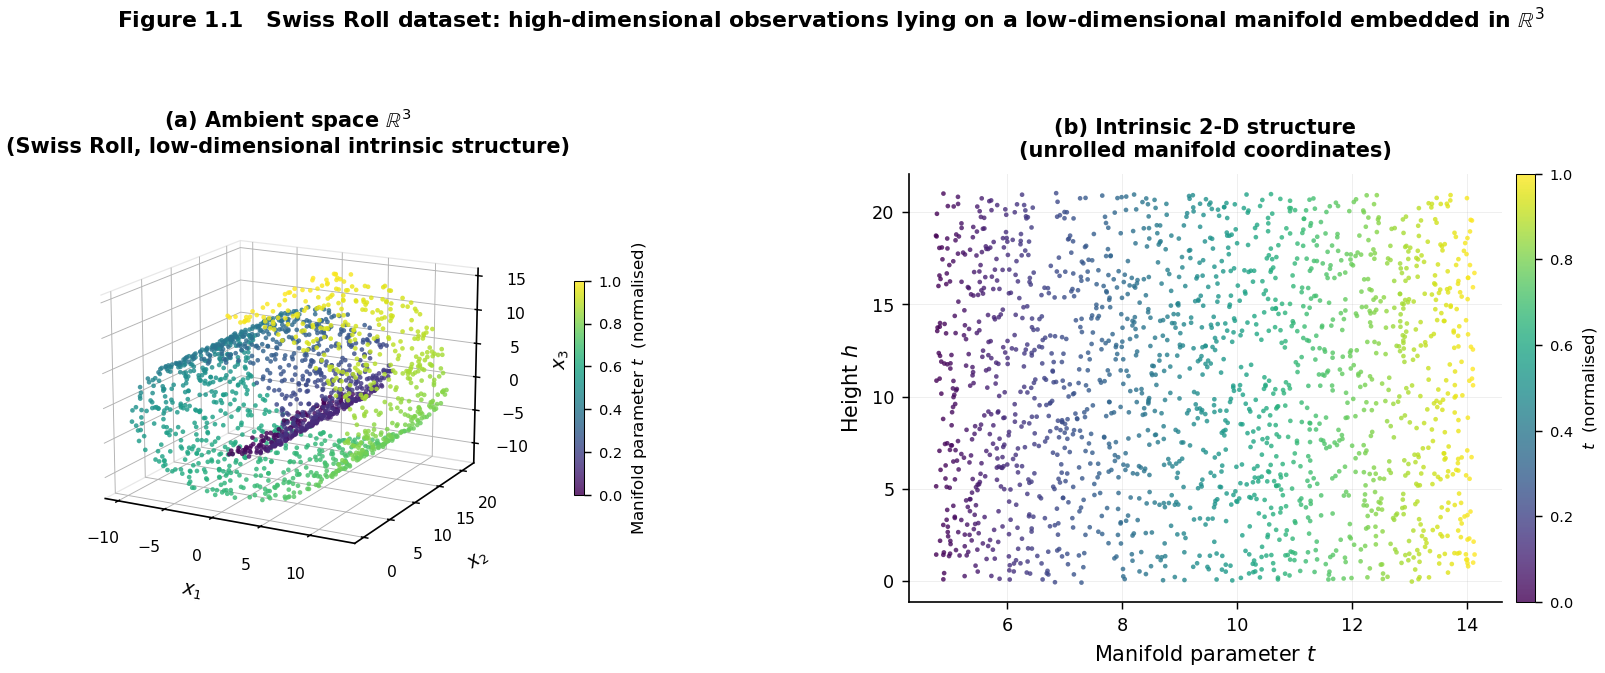

Figure 1.1 saved  (fig1_1_swiss_roll.pdf, 300 DPI)


In [6]:
# ── Figure 1.1  Swiss Roll: high-dim data lying on a low-dim manifold ──────
n = 1800
X_roll, t_roll = make_swiss_roll(n_samples=n, noise=0.10, random_state=42)
t_norm = (t_roll - t_roll.min()) / (t_roll.max() - t_roll.min())

fig = plt.figure(figsize=(12, 5.6))
fig.set_layout_engine('none')
# top=0.60: plot area ends at 60% of figure height, leaving 40% clear above
# so the 2-line panel titles + 2-line suptitle NEVER share the same band
fig.subplots_adjust(left=0.02, right=0.94, top=0.60, bottom=0.09, wspace=0.32)

# ── Panel (a): 3-D ambient space ──────────────────────────────────────────
ax1 = fig.add_subplot(121, projection='3d')
sc1 = ax1.scatter(X_roll[:, 0], X_roll[:, 1], X_roll[:, 2],
                  c=t_norm, s=5, cmap='viridis', alpha=0.82, linewidths=0,
                  rasterized=True)

for pane in [ax1.xaxis.pane, ax1.yaxis.pane, ax1.zaxis.pane]:
    pane.fill = False
    pane.set_edgecolor('0.82')
ax1.grid(True, linewidth=0.35, alpha=0.35)
ax1.set_xlabel('$x_1$', labelpad=5, fontsize=9)
ax1.set_ylabel('$x_2$', labelpad=5, fontsize=9)
ax1.set_zlabel('$x_3$', labelpad=5, fontsize=9)
ax1.tick_params(labelsize=7.5)
ax1.view_init(elev=16, azim=-62)
ax1.set_title(r'(a) Ambient space $\mathbb{R}^{3}$'
              '\n(Swiss Roll, low-dimensional intrinsic structure)', fontsize=10, fontweight='bold', pad=10)

cb1 = fig.colorbar(sc1, ax=ax1, shrink=0.50, pad=0.10, aspect=20,
                   orientation='vertical')
cb1.set_label('Manifold parameter $t$  (normalised)', fontsize=8)
cb1.ax.tick_params(labelsize=7)
cb1.outline.set_linewidth(0.5)

# ── Panel (b): unrolled intrinsic 2-D coordinates ─────────────────────────
ax2 = fig.add_subplot(122)
sc2 = ax2.scatter(t_roll, X_roll[:, 1], c=t_norm, s=5,
                  cmap='viridis', alpha=0.80, linewidths=0, rasterized=True)
ax2.set_xlabel('Manifold parameter $t$')
ax2.set_ylabel('Height $h$')
ax2.set_title('(b) Intrinsic 2-D structure\n(unrolled manifold coordinates)',
              fontsize=10, fontweight='bold')

cb2 = fig.colorbar(sc2, ax=ax2, aspect=22, pad=0.02)
cb2.set_label('$t$  (normalised)', fontsize=8)
cb2.ax.tick_params(labelsize=7)
cb2.outline.set_linewidth(0.5)

fig.suptitle(
    'Figure 1.1   Swiss Roll dataset: high-dimensional observations lying on a'
    ' low-dimensional manifold embedded in $\\mathbb{R}^{3}$',
    fontsize=10.5, fontweight='bold', y=0.8)

fig.savefig('pictures/fig1_1_swiss_roll.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Figure 1.1 saved  (fig1_1_swiss_roll.pdf, 300 DPI)")

### Sensor Stream Example — Nonlinear Dynamics in Practice

A concrete real-world instance of the manifold hypothesis is a **physical sensor stream** governed by nonlinear differential equations.  
The **Lorenz system** is a canonical model of such behaviour — originally derived to describe atmospheric convection, it is representative of coupled sensor signals in robotics, climate monitoring, and industrial process control:

$$\dot{x} = \sigma(y - x), \qquad \dot{y} = x(\rho - z) - y, \qquad \dot{z} = xy - \beta z$$

with parameters $\sigma = 10,\; \rho = 28,\; \beta = \tfrac{8}{3}$.

Although the system produces **three sensor channels** (ambient dimension $d = 3$), the long-run trajectory lies on the Lorenz strange attractor, whose effective dimension is substantially lower than the ambient space.  
This is precisely the mismatch that linear methods like PCA struggle with: dominant Euclidean variance directions can cut across attractor geometry rather than following intrinsic dynamics.

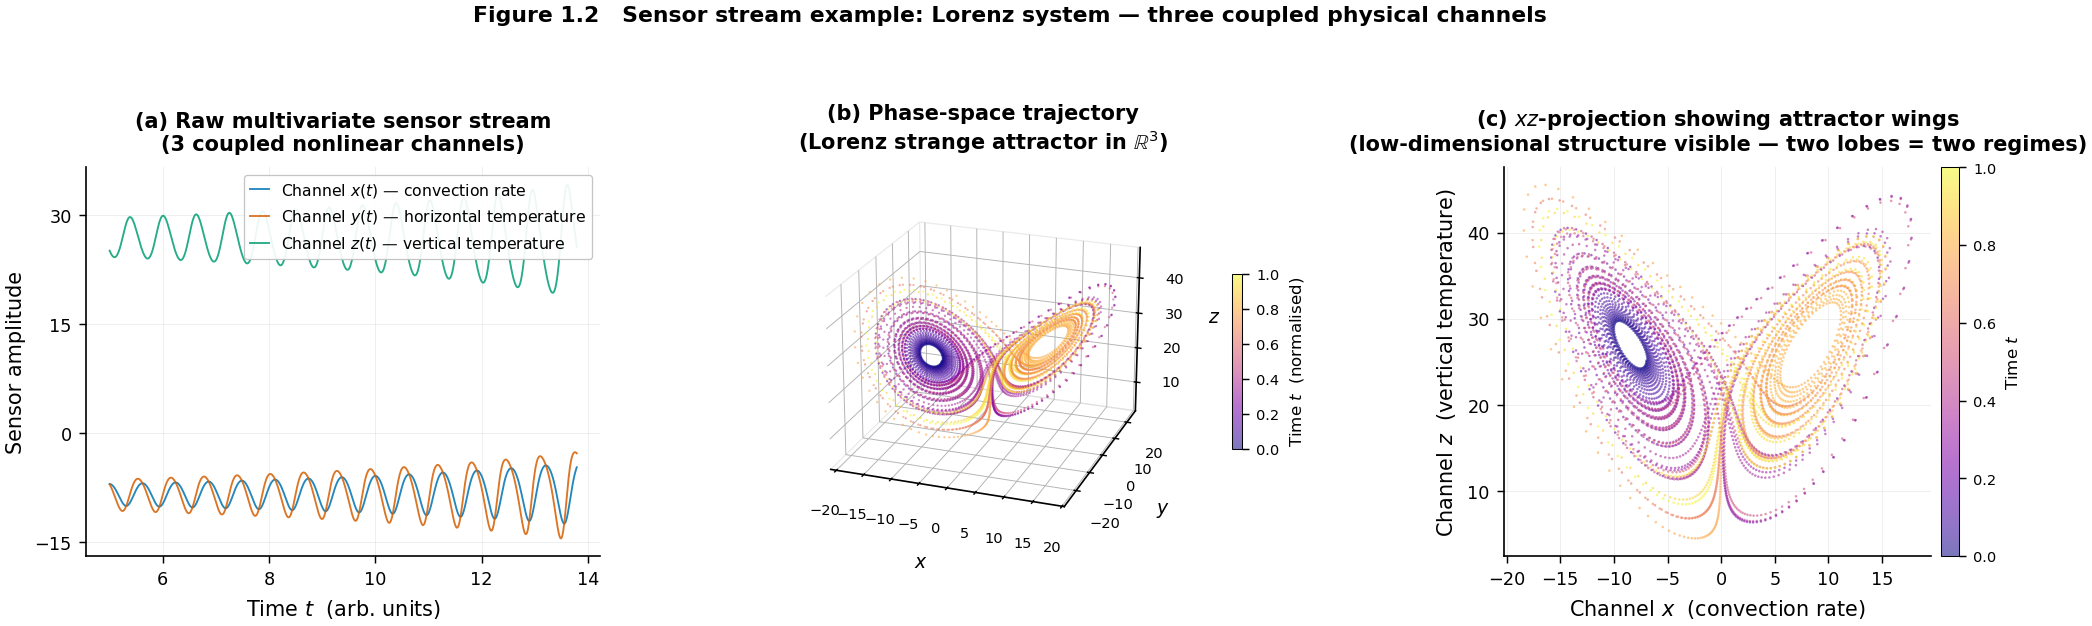

Figure 1.2 saved  (fig1_2_sensor_lorenz.pdf, 300 DPI)


In [5]:

# ── Figure 1.2  Sensor stream: Lorenz attractor ──────────────────────────
from scipy.integrate import solve_ivp

# ── Integrate Lorenz system ────────────────────────────────────────────────
def _lorenz(t, s, sigma=10.0, rho=28.0, beta=8/3):
    x, y, z = s
    return [sigma * (y - x), x * (rho - z) - y, x * y - beta * z]

sol = solve_ivp(_lorenz, [0, 60], [1.0, 0.0, 0.0],
                method='DOP853', dense_output=False,
                t_eval=np.linspace(5, 60, 5000),   # discard transient [0,5]
                rtol=1e-10, atol=1e-12)

t_lor  = sol.t                      # (5000,)
X_lor  = sol.y.T                    # (5000, 3)  — three sensor channels
labels = ['Channel $x(t)$ — convection rate',
          'Channel $y(t)$ — horizontal temperature',
          'Channel $z(t)$ — vertical temperature']
ch_col = [CB['blue'], CB['red'], CB['green']]

# Colour phase-space points by time for trajectory colouring
t_norm_lor = (t_lor - t_lor.min()) / (t_lor.max() - t_lor.min())

# ── Build figure (3 panels, no constrained layout — 3-D panel present) ─────
fig = plt.figure(figsize=(14, 5.4))
fig.set_layout_engine('none')
# top=0.60 guarantees the suptitle and panel titles never share the same vertical band
fig.subplots_adjust(left=0.06, right=0.98, top=0.60,
                    bottom=0.12, wspace=0.38)

# ── Panel (a): raw sensor time-series (first 800 samples) ─────────────────
ax_ts = fig.add_subplot(131)
n_show = 800
for ch, col, lbl in zip(range(3), ch_col, labels):
    ax_ts.plot(t_lor[:n_show], X_lor[:n_show, ch],
               color=col, linewidth=0.9, alpha=0.85, label=lbl)
ax_ts.set_xlabel('Time $t$  (arb. units)')
ax_ts.set_ylabel('Sensor amplitude')
ax_ts.set_title('(a) Raw multivariate sensor stream\n'
                '(3 coupled nonlinear channels)', fontsize=10, fontweight='bold')
ax_ts.legend(loc='upper right', fontsize=7.5, framealpha=0.92, edgecolor='0.75',
             handlelength=1.2)
ax_ts.yaxis.set_major_locator(ticker.MaxNLocator(5))

# ── Panel (b): 3-D phase space — attractor manifold ───────────────────────
ax_3d = fig.add_subplot(132, projection='3d')
sc_3d = ax_3d.scatter(X_lor[:, 0], X_lor[:, 1], X_lor[:, 2],
                      c=t_norm_lor, cmap='plasma', s=1.2,
                      alpha=0.55, linewidths=0, rasterized=True)

for pane in [ax_3d.xaxis.pane, ax_3d.yaxis.pane, ax_3d.zaxis.pane]:
    pane.fill = False
    pane.set_edgecolor('0.84')
ax_3d.grid(True, linewidth=0.3, alpha=0.3)
ax_3d.set_xlabel('$x$', labelpad=4, fontsize=9)
ax_3d.set_ylabel('$y$', labelpad=4, fontsize=9)
ax_3d.set_zlabel('$z$', labelpad=4, fontsize=9)
ax_3d.tick_params(labelsize=7)
ax_3d.view_init(elev=22, azim=290)
ax_3d.set_title('(b) Phase-space trajectory\n'
                '(Lorenz strange attractor in $\\mathbb{R}^3$)',
                fontsize=10, fontweight='bold', pad=12)

cb_3d = fig.colorbar(sc_3d, ax=ax_3d, shrink=0.45, pad=0.12,
                     aspect=18, orientation='vertical')
cb_3d.set_label('Time $t$  (normalised)', fontsize=8)
cb_3d.ax.tick_params(labelsize=7)
cb_3d.outline.set_linewidth(0.5)

# ── Panel (c): 2-D projection showing wing structure ──────────────────────
ax_2d = fig.add_subplot(133)
sc_2d = ax_2d.scatter(X_lor[:, 0], X_lor[:, 2],
                      c=t_norm_lor, cmap='plasma', s=1.5,
                      alpha=0.55, linewidths=0, rasterized=True)
ax_2d.set_xlabel('Channel $x$  (convection rate)')
ax_2d.set_ylabel('Channel $z$  (vertical temperature)')
ax_2d.set_title('(c) $xz$-projection showing attractor wings\n'
                '(low-dimensional structure visible — two lobes = two regimes)',
                fontsize=10, fontweight='bold')

cb_2d = fig.colorbar(sc_2d, ax=ax_2d, aspect=22, pad=0.02)
cb_2d.set_label('Time $t$', fontsize=8)
cb_2d.ax.tick_params(labelsize=7)
cb_2d.outline.set_linewidth(0.5)

fig.suptitle(
    'Figure 1.2   Sensor stream example: Lorenz system — three coupled physical channels',
    fontsize=10.5, fontweight='bold', y=0.8)

fig.savefig('pictures/fig1_2_sensor_lorenz.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Figure 1.2 saved  (fig1_2_sensor_lorenz.pdf, 300 DPI)")


---
## 1.2 Conventional Linear Solution: PCA

**Principal Component Analysis (PCA)** is the most widely used baseline for dimensionality reduction, valued for its:

- Mathematical simplicity & computational efficiency  
- Clear *variance-explained* interpretation  
- Stable behaviour on moderately linear problems  

### Formulation

Given centred observations $X \in \mathbb{R}^{n \times d}$, PCA solves:

$$\max_{U^\top U = I_m} \;\mathrm{Tr}\!\left(U^\top \Sigma\, U\right)$$

where $\Sigma$ is the sample covariance matrix and $m \ll d$ is the target dimension.

The solution projects $X$ onto the **leading $m$ eigenvectors** of $\Sigma$ (the principal components).

> PCA is an **essential reference point** for any study on nonlinear embedding methods — we will use it as the primary comparison baseline throughout this report.

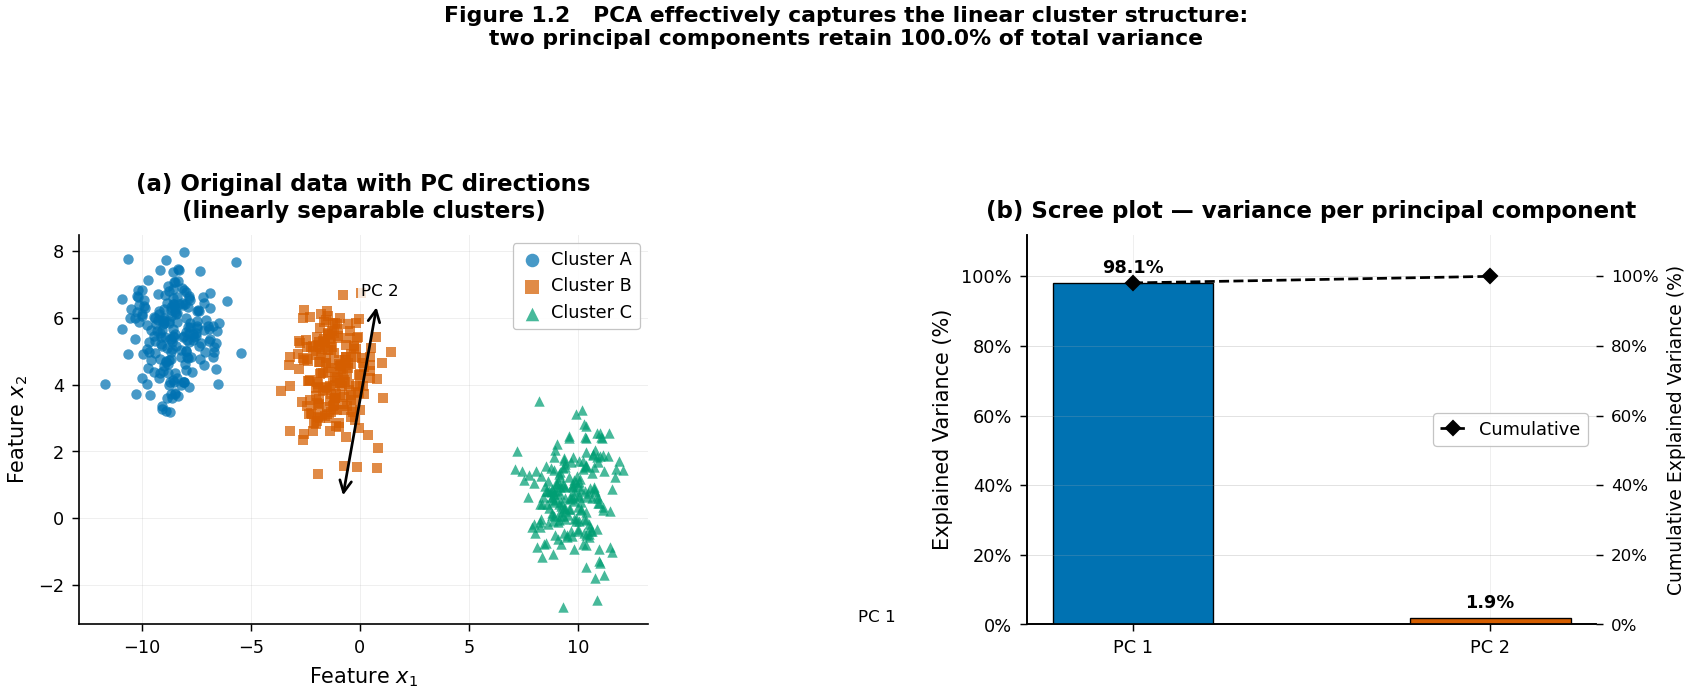

Figure 1.2 saved  (fig1_2_pca_linear.pdf, 300 DPI)


In [ ]:

# ── Figure 1.3  PCA on linearly separable data ────────────────────────────
X_blobs, y_blobs = make_blobs(n_samples=600, centers=3,
                               cluster_std=1.05, random_state=7)
pca_2d  = PCA(n_components=2)
X_pca2  = pca_2d.fit_transform(X_blobs)
varexp  = pca_2d.explained_variance_ratio_
cumvar  = np.cumsum(varexp)

CL_COLORS  = [CB['blue'], CB['red'], CB['green']]
CL_MARKERS = ['o', 's', '^']
CL_NAMES   = ['Cluster A', 'Cluster B', 'Cluster C']

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))

# ── Panel (a): original scatter + PC arrows ────────────────────────────────
for k in range(3):
    mask = y_blobs == k
    axes[0].scatter(X_blobs[mask, 0], X_blobs[mask, 1],
                    c=CL_COLORS[k], marker=CL_MARKERS[k],
                    s=25, alpha=0.72, linewidths=0,
                    label=CL_NAMES[k], zorder=3)

mu = X_blobs.mean(axis=0)
for comp, ev, lbl in zip(pca_2d.components_,
                          pca_2d.explained_variance_,
                          ['PC 1', 'PC 2']):
    scale = 2.8 * np.sqrt(ev)
    axes[0].annotate(
        '', xy=mu + scale * comp, xytext=mu - scale * comp,
        arrowprops=dict(arrowstyle='<->', color='black',
                        lw=1.3, mutation_scale=14))
    axes[0].text(*(mu + scale * comp * 1.12), lbl,
                 fontsize=8, ha='center', va='center',
                 bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.8))

axes[0].set_xlabel('Feature $x_1$')
axes[0].set_ylabel('Feature $x_2$')
axes[0].set_title('(a) Original data with PC directions\n'
                  '(linearly separable clusters)')
axes[0].legend(loc='upper right', framealpha=0.92, edgecolor='0.75',
               markerscale=1.3, handletextpad=0.4)

# ── Panel (b): scree plot with cumulative variance ────────────────────────
pc_labels = [f'PC {i+1}' for i in range(len(varexp))]
bars = axes[1].bar(pc_labels, varexp * 100,
                   color=[CB['blue'], CB['red']],
                   edgecolor='black', linewidth=0.65, width=0.45, zorder=3)
for bar, v in zip(bars, varexp):
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 v * 100 + 1.8,
                 f'{v*100:.1f}%', ha='center', va='bottom',
                 fontsize=8.5, fontweight='bold')

ax_twin = axes[1].twinx()
ax_twin.plot(pc_labels, cumvar * 100,
             color=CB['black'], linestyle='--', marker='D',
             markersize=5, linewidth=1.3, label='Cumulative', zorder=4)
ax_twin.set_ylabel('Cumulative Explained Variance (%)', fontsize=9)
ax_twin.set_ylim(0, 112)
ax_twin.spines['top'].set_visible(False)
ax_twin.spines['right'].set_linewidth(0.8)
ax_twin.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=100, decimals=0))
ax_twin.tick_params(labelsize=8)
ax_twin.legend(loc='center right', fontsize=8.5)

axes[1].set_ylabel('Explained Variance (%)')
axes[1].set_ylim(0, 112)
axes[1].yaxis.set_major_formatter(ticker.PercentFormatter(xmax=100, decimals=0))
axes[1].set_title('(b) Scree plot — variance per principal component')

fig.suptitle(
    'Figure 1.3   PCA effectively captures the linear cluster structure:\n'
    f'two principal components retain {cumvar[-1]*100:.1f}% of total variance',
    fontsize=10.5, fontweight='bold')
# rect=[left, bottom, right, top]: reserve top 13% of figure height for suptitle
fig.tight_layout(rect=[0, 0, 1, 0.87])

fig.savefig('pictures/fig1_3_pca_linear.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Figure 1.3 saved  (fig1_3_pca_linear.pdf, 300 DPI)")


---
## 1.3 Limitations of PCA in Nonlinear Structures

PCA is **fundamentally linear**. When data resides on curved manifolds, linear projections can:

| Problem | Consequence |
|---------|-------------|
| Distort neighbourhood relationships | Nearby-on-manifold points map far apart |
| Collapse meaningful transitions | Regime changes become indistinguishable |
| Mix unrelated local structures | Principal components conflate independent variations |
| Artificially bring distant points close | Downstream clustering becomes unstable |

> *"Points that are distant along the manifold may appear **artificially close** after projection."*

The figure below makes this concrete: PCA projection of the Two-Moon dataset, a classic nonlinear structure fails to separate the two clusters, while the true class structure is obvious in 2-D.

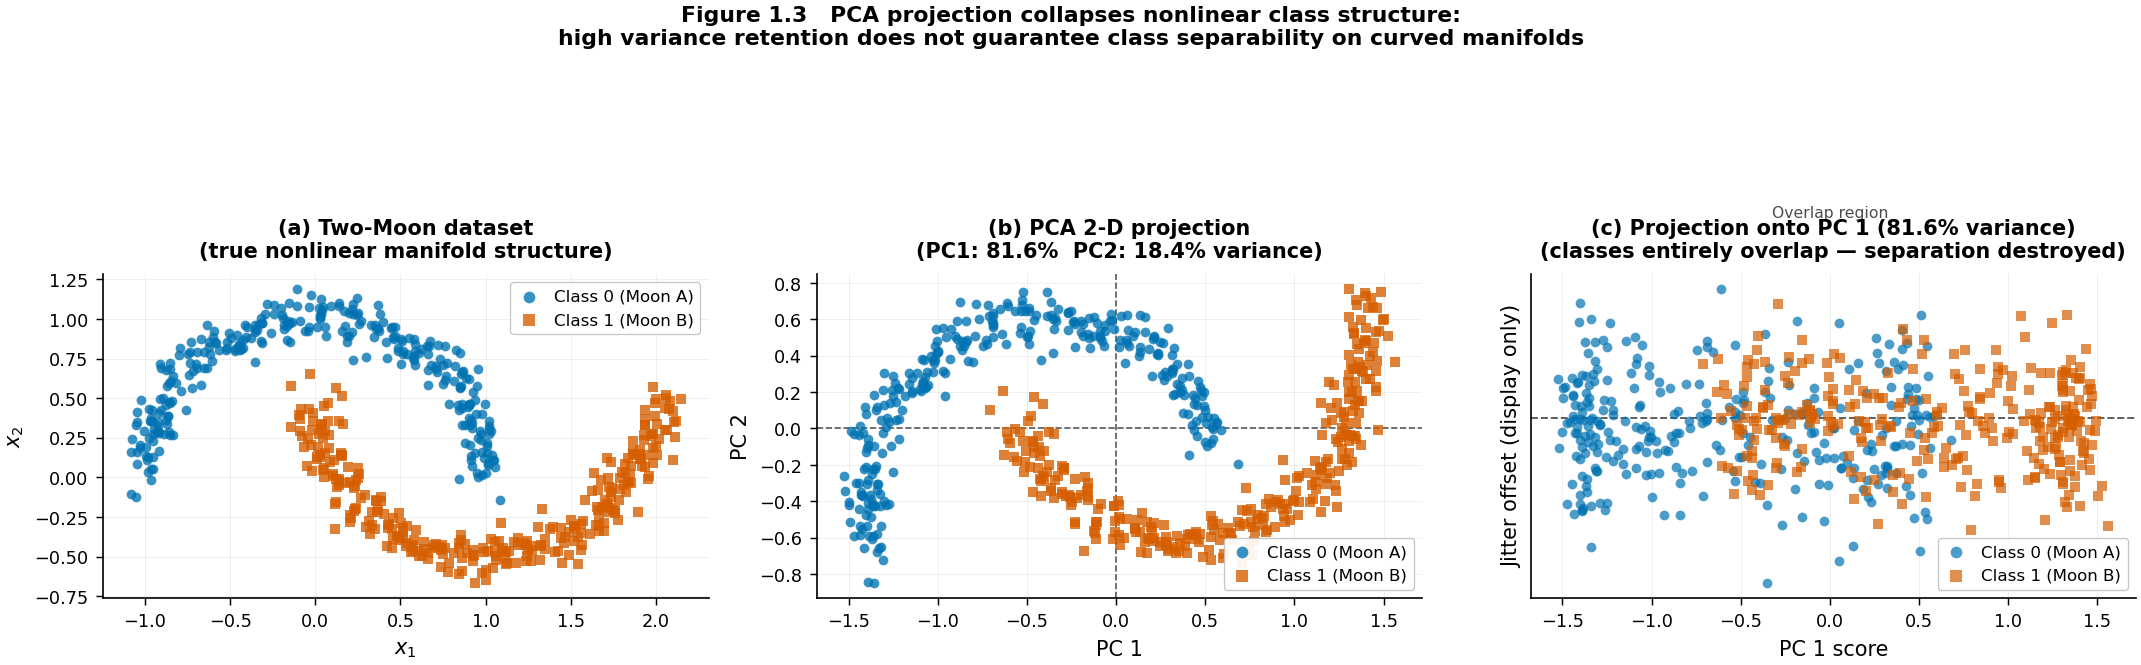

Figure 1.3 saved  (fig1_3_pca_moons.pdf, 300 DPI)


In [ ]:

# ── Figure 1.4  PCA fails on nonlinear (Two-Moon) data ────────────────────
X_moon, y_moon   = make_moons(n_samples=600, noise=0.07, random_state=42)
pca_moon          = PCA(n_components=2)
X_moon_pca        = pca_moon.fit_transform(X_moon)
var1, var2        = pca_moon.explained_variance_ratio_

MOON_COL = [CB['blue'], CB['red']]
MOON_LBL = ['Class 0 (Moon A)', 'Class 1 (Moon B)']
MOON_MRK = ['o', 's']

def _scatter_classes(ax, X, y, s=22, alpha=0.78):
    for k in range(2):
        mask = y == k
        ax.scatter(X[mask, 0], X[mask, 1],
                   c=MOON_COL[k], marker=MOON_MRK[k],
                   s=s, alpha=alpha, linewidths=0,
                   label=MOON_LBL[k], zorder=3, rasterized=True)

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.6))

# ── Panel (a): true nonlinear structure ───────────────────────────────────
_scatter_classes(axes[0], X_moon, y_moon)
axes[0].set_xlabel('$x_1$')
axes[0].set_ylabel('$x_2$')
axes[0].set_title('(a) Two-Moon dataset\n(true nonlinear manifold structure)', fontsize=10)
axes[0].legend(framealpha=0.92, edgecolor='0.75', markerscale=1.2, fontsize=8)

# ── Panel (b): PCA 2-D projection ─────────────────────────────────────────
_scatter_classes(axes[1], X_moon_pca, y_moon)
axes[1].set_xlabel('PC 1')
axes[1].set_ylabel('PC 2')
axes[1].set_title(f'(b) PCA 2-D projection\n'
                  f'(PC1: {var1*100:.1f}%  PC2: {var2*100:.1f}% variance)',
                  fontsize=10)
axes[1].legend(framealpha=0.92, edgecolor='0.75', markerscale=1.2, fontsize=8)
axes[1].axhline(0, color='0.35', linewidth=0.8, linestyle='--', zorder=1)
axes[1].axvline(0, color='0.35', linewidth=0.8, linestyle='--', zorder=1)

# ── Panel (c): 1-D projection — complete class overlap ────────────────────
rng    = np.random.default_rng(7)
jitter = rng.normal(0, 0.016, len(X_moon))
pc1    = X_moon_pca[:, 0]

for k in range(2):
    mask = y_moon == k
    axes[2].scatter(pc1[mask], jitter[mask],
                    c=MOON_COL[k], marker=MOON_MRK[k],
                    s=22, alpha=0.70, linewidths=0,
                    label=MOON_LBL[k], zorder=3, rasterized=True)

axes[2].axhline(0, color='0.35', linewidth=0.9, linestyle='--', zorder=1)
axes[2].set_xlabel('PC 1 score')
axes[2].set_ylabel('Jitter offset (display only)')
axes[2].set_yticks([])
axes[2].set_title(f'(c) Projection onto PC 1 ({var1*100:.1f}% variance)\n'
                  '(classes entirely overlap — separation destroyed)', fontsize=10)
axes[2].legend(framealpha=0.92, edgecolor='0.75', markerscale=1.2, fontsize=8)

yb = 0.055
axes[2].annotate('',
    xy=(pc1.max() * 0.96, yb), xytext=(pc1.min() * 0.96, yb),
    arrowprops=dict(arrowstyle='<->', color='0.30', lw=1.0))
axes[2].text(pc1.mean(), yb + 0.008, 'Overlap region',
             ha='center', fontsize=7.5, color='0.30')

fig.suptitle(
    'Figure 1.4   PCA projection collapses nonlinear class structure:\n'
    'high variance retention does not guarantee class separability on curved manifolds',
    fontsize=10.5, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.87])

fig.savefig('pictures/fig1_4_pca_moons.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Figure 1.4 saved  (fig1_4_pca_moons.pdf, 300 DPI)")



---
## 1.3b  A Nonlinear Baseline: t-SNE

**t-Distributed Stochastic Neighbor Embedding (t-SNE)** directly targets the problem PCA fails at: it models local, nonlinear structure by matching pairwise similarities between points.

### Formulation

Define the high-dimensional similarity between $x_i$ and $x_j$ using a Gaussian kernel with per-point bandwidth $\sigma_i$:

$$p_{ij} = \frac{p_{j|i} + p_{i|j}}{2n}, \qquad p_{j|i} = \frac{\exp\!\left(-\|x_i - x_j\|^2 / 2\sigma_i^2\right)}{\displaystyle\sum_{k \ne i}\exp\!\left(-\|x_i - x_k\|^2 / 2\sigma_i^2\right)}$$

In the low-dimensional embedding $y_i \in \mathbb{R}^m$, a heavier-tailed Student-$t$ distribution is used:

$$q_{ij} = \frac{\left(1 + \|y_i - y_j\|^2\right)^{-1}}{\displaystyle\sum_{k \ne l}\left(1 + \|y_k - y_l\|^2\right)^{-1}}$$

The embedding is found by minimising the KL-divergence:

$$\mathcal{L} = \mathrm{KL}(P \,\|\, Q) = \sum_{i,j} p_{ij} \log \frac{p_{ij}}{q_{ij}}$$

### Key hyperparameter: Perplexity

The **perplexity** $\mathcal{P}$ controls the effective neighbourhood size and the bandwidth $\sigma_i$ of each Gaussian. It is the most influential hyperparameter — small values focus on very local structure while large values approach a more global view:

| Perplexity | Effect |
|-----------|--------|
| Too small ($< 10$) | Points only see their nearest few neighbours → topology fragments |
| Balanced ($\approx 30$) | Captures local manifold geometry faithfully |
| Too large ($> 80$) | Effective neighbourhood covers most of data → structure collapses |

### Limitations vs. Diffusion Map

| Issue | t-SNE | Diffusion Map |
|-------|-------|---------------|
| Stochastic | Yes — results vary across runs | No — deterministic spectral decomposition |
| Out-of-sample | No — cannot embed new points | Yes — via Nyström extension |
| Global geometry | **Not preserved** — cluster spacings are meaningless | Preserved via diffusion distance |
| Interpretability | Low — axes have no meaning | Higher — each axis = diffusion coordinate |

> *t-SNE often produces visually appealing clusters, but the **distances between clusters are not interpretable** — only local structure is preserved.*  
> Diffusion Map retains a coherent multi-scale geometry that supports downstream analysis beyond visualisation.


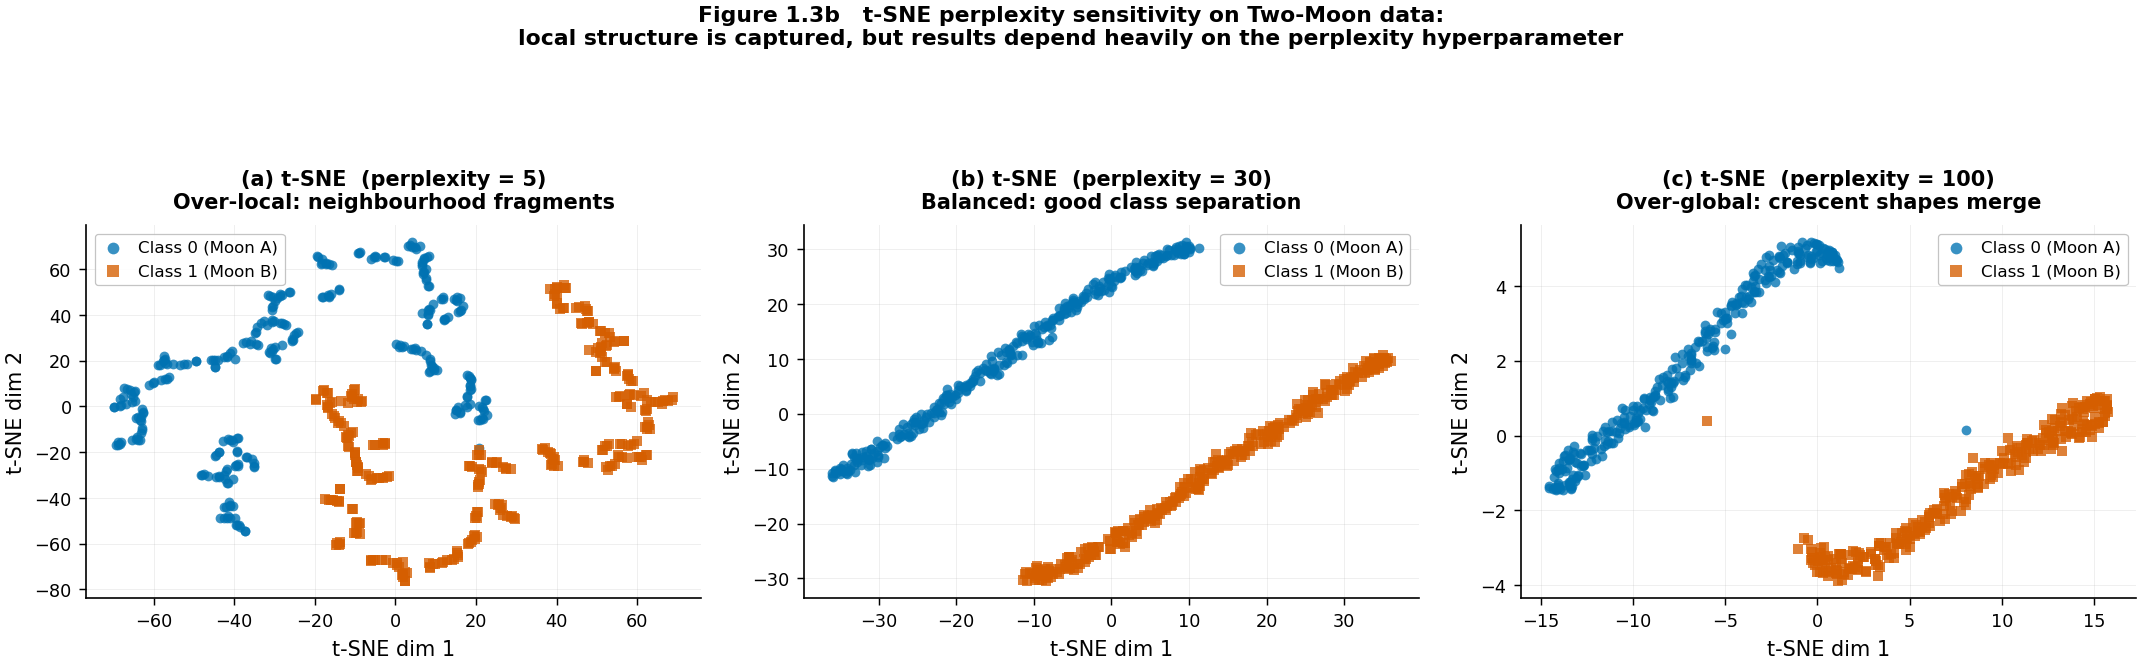

In [ ]:

# ── Figure 1.5  t-SNE: perplexity sensitivity on Two-Moon ────────────────
from sklearn.manifold import TSNE

X_tsne, y_tsne = make_moons(n_samples=600, noise=0.07, random_state=42)

perplexities  = [5, 30, 100]
panel_labels  = ['(a)', '(b)', '(c)']
panel_descs   = [
    't-SNE  (perplexity = 5)\nOver-local: neighbourhood fragments',
    't-SNE  (perplexity = 30)\nBalanced: good class separation',
    't-SNE  (perplexity = 100)\nOver-global: crescent shapes merge',
]

MOON_C = [CB['blue'], CB['red']]
MOON_L = ['Class 0 (Moon A)', 'Class 1 (Moon B)']
MOON_M = ['o', 's']

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.6))

for ax, perp, plbl, pdesc in zip(axes, perplexities, panel_labels, panel_descs):
    tsne  = TSNE(n_components=2, perplexity=perp,
                 init='pca', learning_rate='auto',
                 random_state=42)
    X_emb = tsne.fit_transform(X_tsne)

    for k in range(2):
        mask = y_tsne == k
        ax.scatter(X_emb[mask, 0], X_emb[mask, 1],
                   c=MOON_C[k], marker=MOON_M[k],
                   s=22, alpha=0.78, linewidths=0,
                   label=MOON_L[k], zorder=3, rasterized=True)

    ax.set_xlabel('t-SNE dim 1')
    ax.set_ylabel('t-SNE dim 2')
    ax.set_title(f'{plbl} {pdesc}', fontsize=10, fontweight='bold')
    ax.legend(framealpha=0.92, edgecolor='0.75', markerscale=1.2, fontsize=8)

fig.suptitle(
    'Figure 1.5   t-SNE perplexity sensitivity on Two-Moon data:\n'
    'local structure is captured, but results depend heavily on the perplexity hyperparameter',
    fontsize=10.5, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.87])

fig.savefig('pictures/fig1_5_tsne_perplexity.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Figure 1.5 saved  (fig1_5_tsne_perplexity.pdf, 300 DPI)")


---
## 1.4 Diffusion Map as a Nonlinear Alternative

**Diffusion Map** addresses PCA's limitations by replacing linear variance maximisation with **graph-based diffusion geometry**.

### Core pipeline

```
Raw data X  ──►  Affinity graph W  ──►  Markov random walk P  ──►  Spectral embedding
             (kernel similarities)    (diffusion operator)        (diffusion coordinates)
```

### Two key advantages

**① Local neighbourhoods are encoded explicitly**  
Kernel-based affinities make Diffusion Map sensitive to *manifold structure* rather than only global variance.

**② Diffusion time is a natural scale parameter**  
The diffusion time $t$ smooths noise while preserving large-scale connectivity — tunable without recomputing eigenvectors.

$$k(x_i, x_j) = \exp\!\left(-\frac{\|x_i - x_j\|^2}{\varepsilon}\right)$$

The diffusion distance between two points $x_i, x_j$ after $t$ steps is:

$$D_t(x_i,\, x_j)^2 = \sum_{k \geq 1} \left(\lambda_k^t\right)^2 \bigl(\psi_k(x_i) - \psi_k(x_j)\bigr)^2$$

where $\lambda_k, \psi_k$ are eigenvalues/eigenvectors of the normalised diffusion operator.

> *Diffusion Map can capture both **local** and **global** organisation in a single embedding space.*

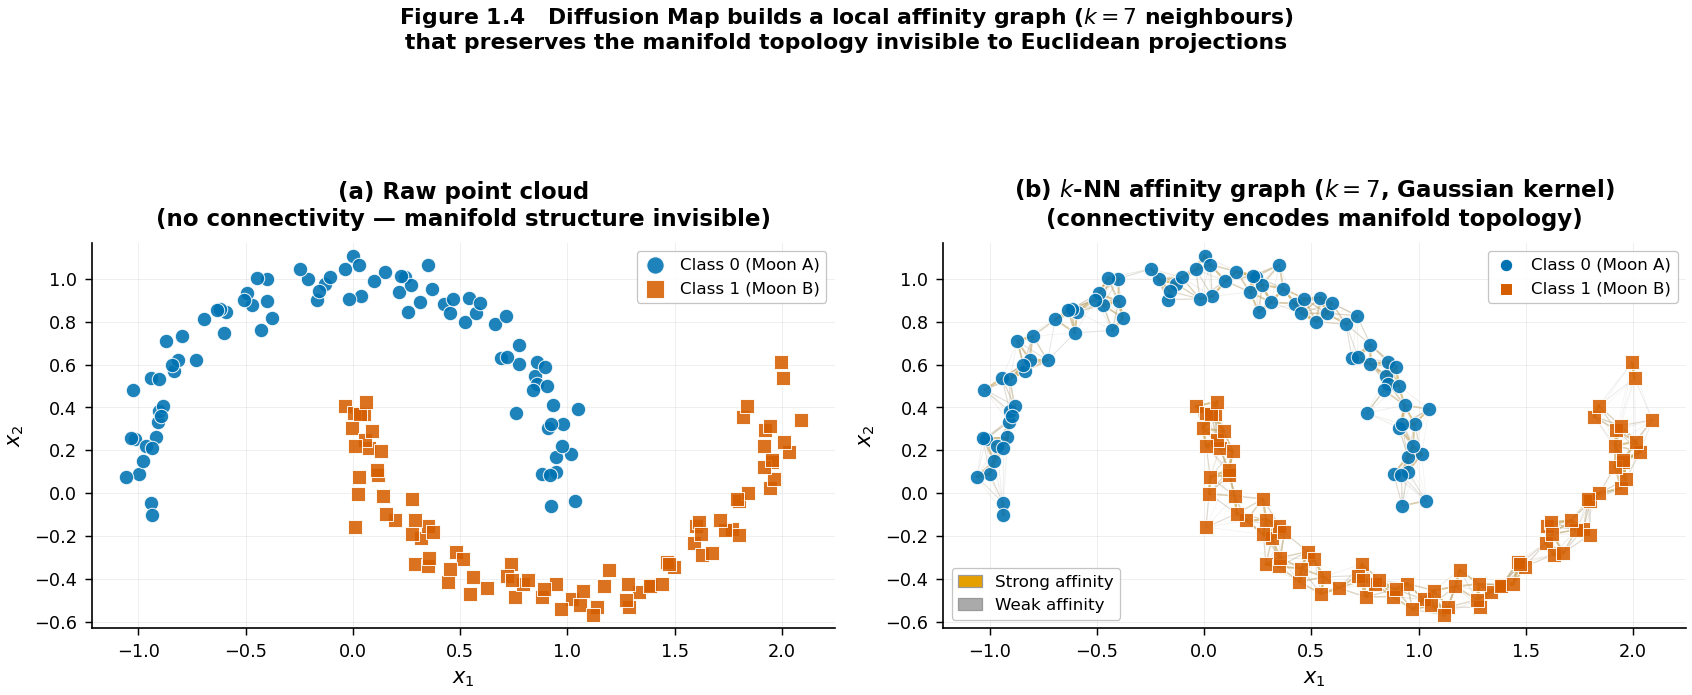

Figure 1.4 saved  (fig1_4_affinity_graph.pdf, 300 DPI)


In [ ]:

# ── Figure 1.6  Affinity graph follows manifold geometry ──────────────────
K = 7
X_small, y_small = make_moons(n_samples=180, noise=0.06, random_state=0)
knn_graph = kneighbors_graph(X_small, n_neighbors=K, mode='connectivity',
                              include_self=False)
cx = sp.coo_matrix(knn_graph)

sq_d   = np.sum((X_small[cx.row] - X_small[cx.col]) ** 2, axis=1)
eps    = np.median(sq_d)
w_edge = np.exp(-sq_d / eps)

MOON_COL = [CB['blue'], CB['red']]
MOON_LBL = ['Class 0 (Moon A)', 'Class 1 (Moon B)']
MOON_MRK = ['o', 's']

EDGE_STRONG = CB['orange']
EDGE_WEAK   = '#AAAAAA'

def _draw_nodes(ax, X, y, s=48):
    for k in range(2):
        mask = y == k
        ax.scatter(X[mask, 0], X[mask, 1],
                   c=MOON_COL[k], marker=MOON_MRK[k],
                   s=s, alpha=0.88, edgecolors='white',
                   linewidths=0.5, zorder=4, label=MOON_LBL[k])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))

# ── Panel (a): raw point cloud ─────────────────────────────────────────────
_draw_nodes(axes[0], X_small, y_small)
axes[0].set_xlabel('$x_1$')
axes[0].set_ylabel('$x_2$')
axes[0].set_title('(a) Raw point cloud\n'
                  '(no connectivity — manifold structure invisible)')
axes[0].legend(framealpha=0.92, edgecolor='0.75', markerscale=1.2, fontsize=8,
               loc='upper right')
axes[0].set_aspect('equal', adjustable='datalim')

# ── Panel (b): k-NN affinity graph — edges coloured by weight ─────────────
for i, j, w in zip(cx.row, cx.col, w_edge):
    xi, xj = X_small[i], X_small[j]
    r = float(w)
    color = (
        (1 - r) * np.array(mpl.colors.to_rgb(EDGE_WEAK)) +
        r        * np.array(mpl.colors.to_rgb(EDGE_STRONG))
    )
    axes[1].plot([xi[0], xj[0]], [xi[1], xj[1]],
                 color=color,
                 alpha=r * 0.55 + 0.15,
                 linewidth=r * 1.4 + 0.3,
                 solid_capstyle='round', zorder=1)

_draw_nodes(axes[1], X_small, y_small)
axes[1].set_xlabel('$x_1$')
axes[1].set_ylabel('$x_2$')
axes[1].set_title(f'(b) $k$-NN affinity graph ($k = {K}$, Gaussian kernel)\n'
                  '(connectivity encodes manifold topology)')
axes[1].set_aspect('equal', adjustable='datalim')

# ── Legend 1: class markers — upper right ────────────────────────────────
node_handles = [
    plt.scatter([], [], c=MOON_COL[k], marker=MOON_MRK[k], s=36,
                label=MOON_LBL[k], edgecolors='white', linewidths=0.5)
    for k in range(2)
]
leg1 = axes[1].legend(handles=node_handles, loc='upper right',
                      framealpha=0.92, edgecolor='0.75', fontsize=8)
axes[1].add_artist(leg1)

# ── Legend 2: edge colours — lower left ──────────────────────────────────
edge_handles = [
    mpatches.Patch(facecolor=EDGE_STRONG, edgecolor='0.6', label='Strong affinity'),
    mpatches.Patch(facecolor=EDGE_WEAK,   edgecolor='0.6', label='Weak affinity'),
]
axes[1].legend(handles=edge_handles, loc='lower left',
               framealpha=0.92, edgecolor='0.75', fontsize=8)

fig.suptitle(
    f'Figure 1.6   Diffusion Map builds a local affinity graph ($k = {K}$ neighbours)\n'
    'that preserves the manifold topology invisible to Euclidean projections',
    fontsize=10.5, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.87])

fig.savefig('pictures/fig1_6_affinity_graph.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Figure 1.6 saved  (fig1_6_affinity_graph.pdf, 300 DPI)")



---
## 1.5 Objectives and Scope of This Report

This report develops an **academic and implementation-oriented study** of Technical Diffusion Map with the following goals:

1. **Mathematical foundation** — Formulate the method from affinity construction to spectral embedding.  
2. **Reproducible workflow** — Establish a clear strategy for parameter selection and computational implementation.  
3. **Comparative evaluation** — Compare Diffusion Map with PCA and t-SNE under consistent evaluation criteria.  
4. **Practical analysis** — Analyse strengths, limitations, and deployment considerations for technical data.  

### Scope

> The focus is on **methodological rigour and empirical interpretability** rather than proposing a new manifold-learning algorithm.  
> The intended contribution is a clear bridge between *theoretical formulation* and *practical usage* in data-analysis pipelines.

---
## 1.6 Report Organisation

| Chapter | Title | Content |
|---------|-------|---------|
| **2** | Theoretical Foundation | Graph construction, transition operators, diffusion distance |
| **3** | Methodology | Implementation workflow, hyperparameter strategy |
| **4** | Experiments & Results | Comparative experiments, quantitative evaluation |
| **5** | Discussion & Conclusion | Implications, limitations, concluding remarks |

---

**End of Chapter 1 — Introduction**  
➡ Proceed to [Chapter 2: Theoretical Foundation](./02_theoretical_foundation.ipynb)
